In [1]:
#Purnomo Jeremy Bambang_202431026
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
#Purnomo Jeremy Bambang_202431026
df = pd.read_csv("wilayah_indonesia.csv")
df

,nama,provinsi,kecamatan,kelurahan,desa,jenis
0,Aceh Barat,Aceh,12,0,322,Kabupaten
1,Aceh Barat Daya,Aceh,9,0,152,Kabupaten
2,Aceh Besar,Aceh,23,0,604,Kabupaten
3,Aceh Jaya,Aceh,9,0,172,Kabupaten
4,Aceh Selatan,Aceh,18,0,260,Kabupaten
...,...,...,...,...,...,...
509,Ternate,Maluku Utara,8,78,0,Kota
510,Tidore Kepulauan,Maluku Utara,8,40,49,Kota
511,Tomohon,Sulawesi Utara,5,44,0,Kota
512,Tual,Maluku,5,3,27,Kota


In [3]:
df.info() #Purnomo Jeremy Bambang_202431026

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 514 entries, 0 to 513
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   nama       514 non-null    object
 1   provinsi   514 non-null    object
 2   kecamatan  514 non-null    int64 
 3   kelurahan  514 non-null    int64 
 4   desa       514 non-null    int64 
 5   jenis      514 non-null    object
dtypes: int64(3), object(3)
memory usage: 24.2+ KB


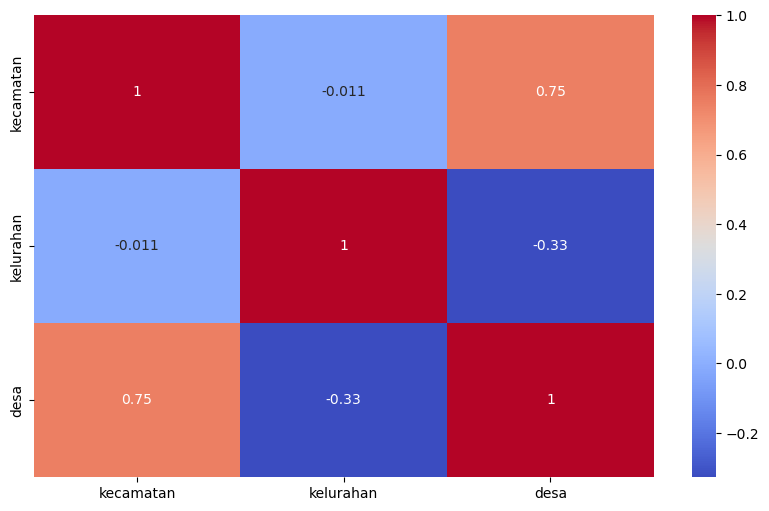

In [4]:
#Purnomo Jeremy Bambang_202431026
num_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(10,6))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm")
plt.show()

In [5]:
#Purnomo Jeremy Bambang_202431026
#buang data kosong pada kolom x dan y
db_clean = df.dropna(subset=["kecamatan", "kelurahan", "desa"])
print(db_clean.shape)

(514, 6)


In [6]:
#Purnomo Jeremy Bambang_202431026
#menentukan x (fitur) dan y (target)
x = db_clean[["kecamatan", "kelurahan"]]
y = db_clean["desa"]

In [7]:
#Purnomo Jeremy Bambang_202431026
#memisah data menjadi data latih dan data test
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [8]:
#Purnomo Jeremy Bambang_202431026
model = LinearRegression()

In [9]:
#Purnomo Jeremy Bambang_202431026
model.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [10]:
#Purnomo Jeremy Bambang_202431026
#prediksi
y_pred = model.predict(x_test)

In [11]:
#Purnomo Jeremy Bambang_202431026
#evaluasi
print("Koefisien :", model.coef_)
print("Intercept :", model.intercept_)
print("MSE :", mean_squared_error(y_test, y_pred))
print("R2 Score :", r2_score(y_test, y_pred))

Koefisien : [10.7823862  -1.67992887]
Intercept : 21.743863812963824
MSE : 4734.364665851991
R2 Score : 0.7025668101203989


In [12]:
#Purnomo Jeremy Bambang_202431026
#persamaan regresi
a = model.intercept_
b1, b2 = model.coef_
print(f"Y = {a:.2f} + ({b1:.2f})x1 + ({b2:.2f})x2")
print("dengan Y = desa, x1 = kecamatan, x2 = kelurahan")

Y = 21.74 + (10.78)x1 + (-1.68)x2
dengan Y = desa, x1 = kecamatan, x2 = kelurahan


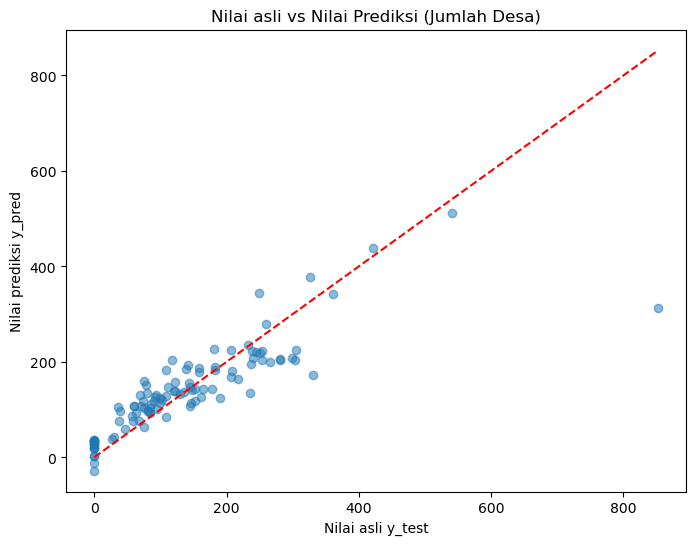

In [13]:
#Purnomo Jeremy Bambang_202431026
##visualisasi model
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Nilai asli y_test")
plt.ylabel("Nilai prediksi y_pred")
plt.title("Nilai asli vs Nilai Prediksi (Jumlah Desa)")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()